start
Starting execution
Executing configuration {'data_dir': 'C:/ProjectData/Projekte/Uni/classif_srch/data\\letters/classification', 'name': 'letters', 'labels': ['author', 'lang'], 'text_label': 'text'}
Running classifier Perceptron on data letters and label author
2026-11-23 14:05:06,632 INFO       Evaluating classifier(s) ['Perceptron']
2026-11-23 14:05:06,633 INFO       Evaluating classification of classifier Perceptron
2026-11-23 14:05:06,971 INFO       Read 39077 training records
2026-11-23 14:05:06,973 INFO       Training classifier Perceptron with text fields ['text'] for label author
2026-11-23 14:05:07,089 INFO       Creating TF-IDF Matrix
2026-11-23 14:05:10,658 INFO       TF-IDF matrix training completed. Dimensions: 26974
INFO: Starting fitting of classifier with 39077 training points.
INFO: Fitting completed
2026-11-23 14:06:35,123 INFO       Training completed in 88 seconds
2026-11-23 14:06:35,125 INFO       Starting classification of data with classifier Perceptron
20

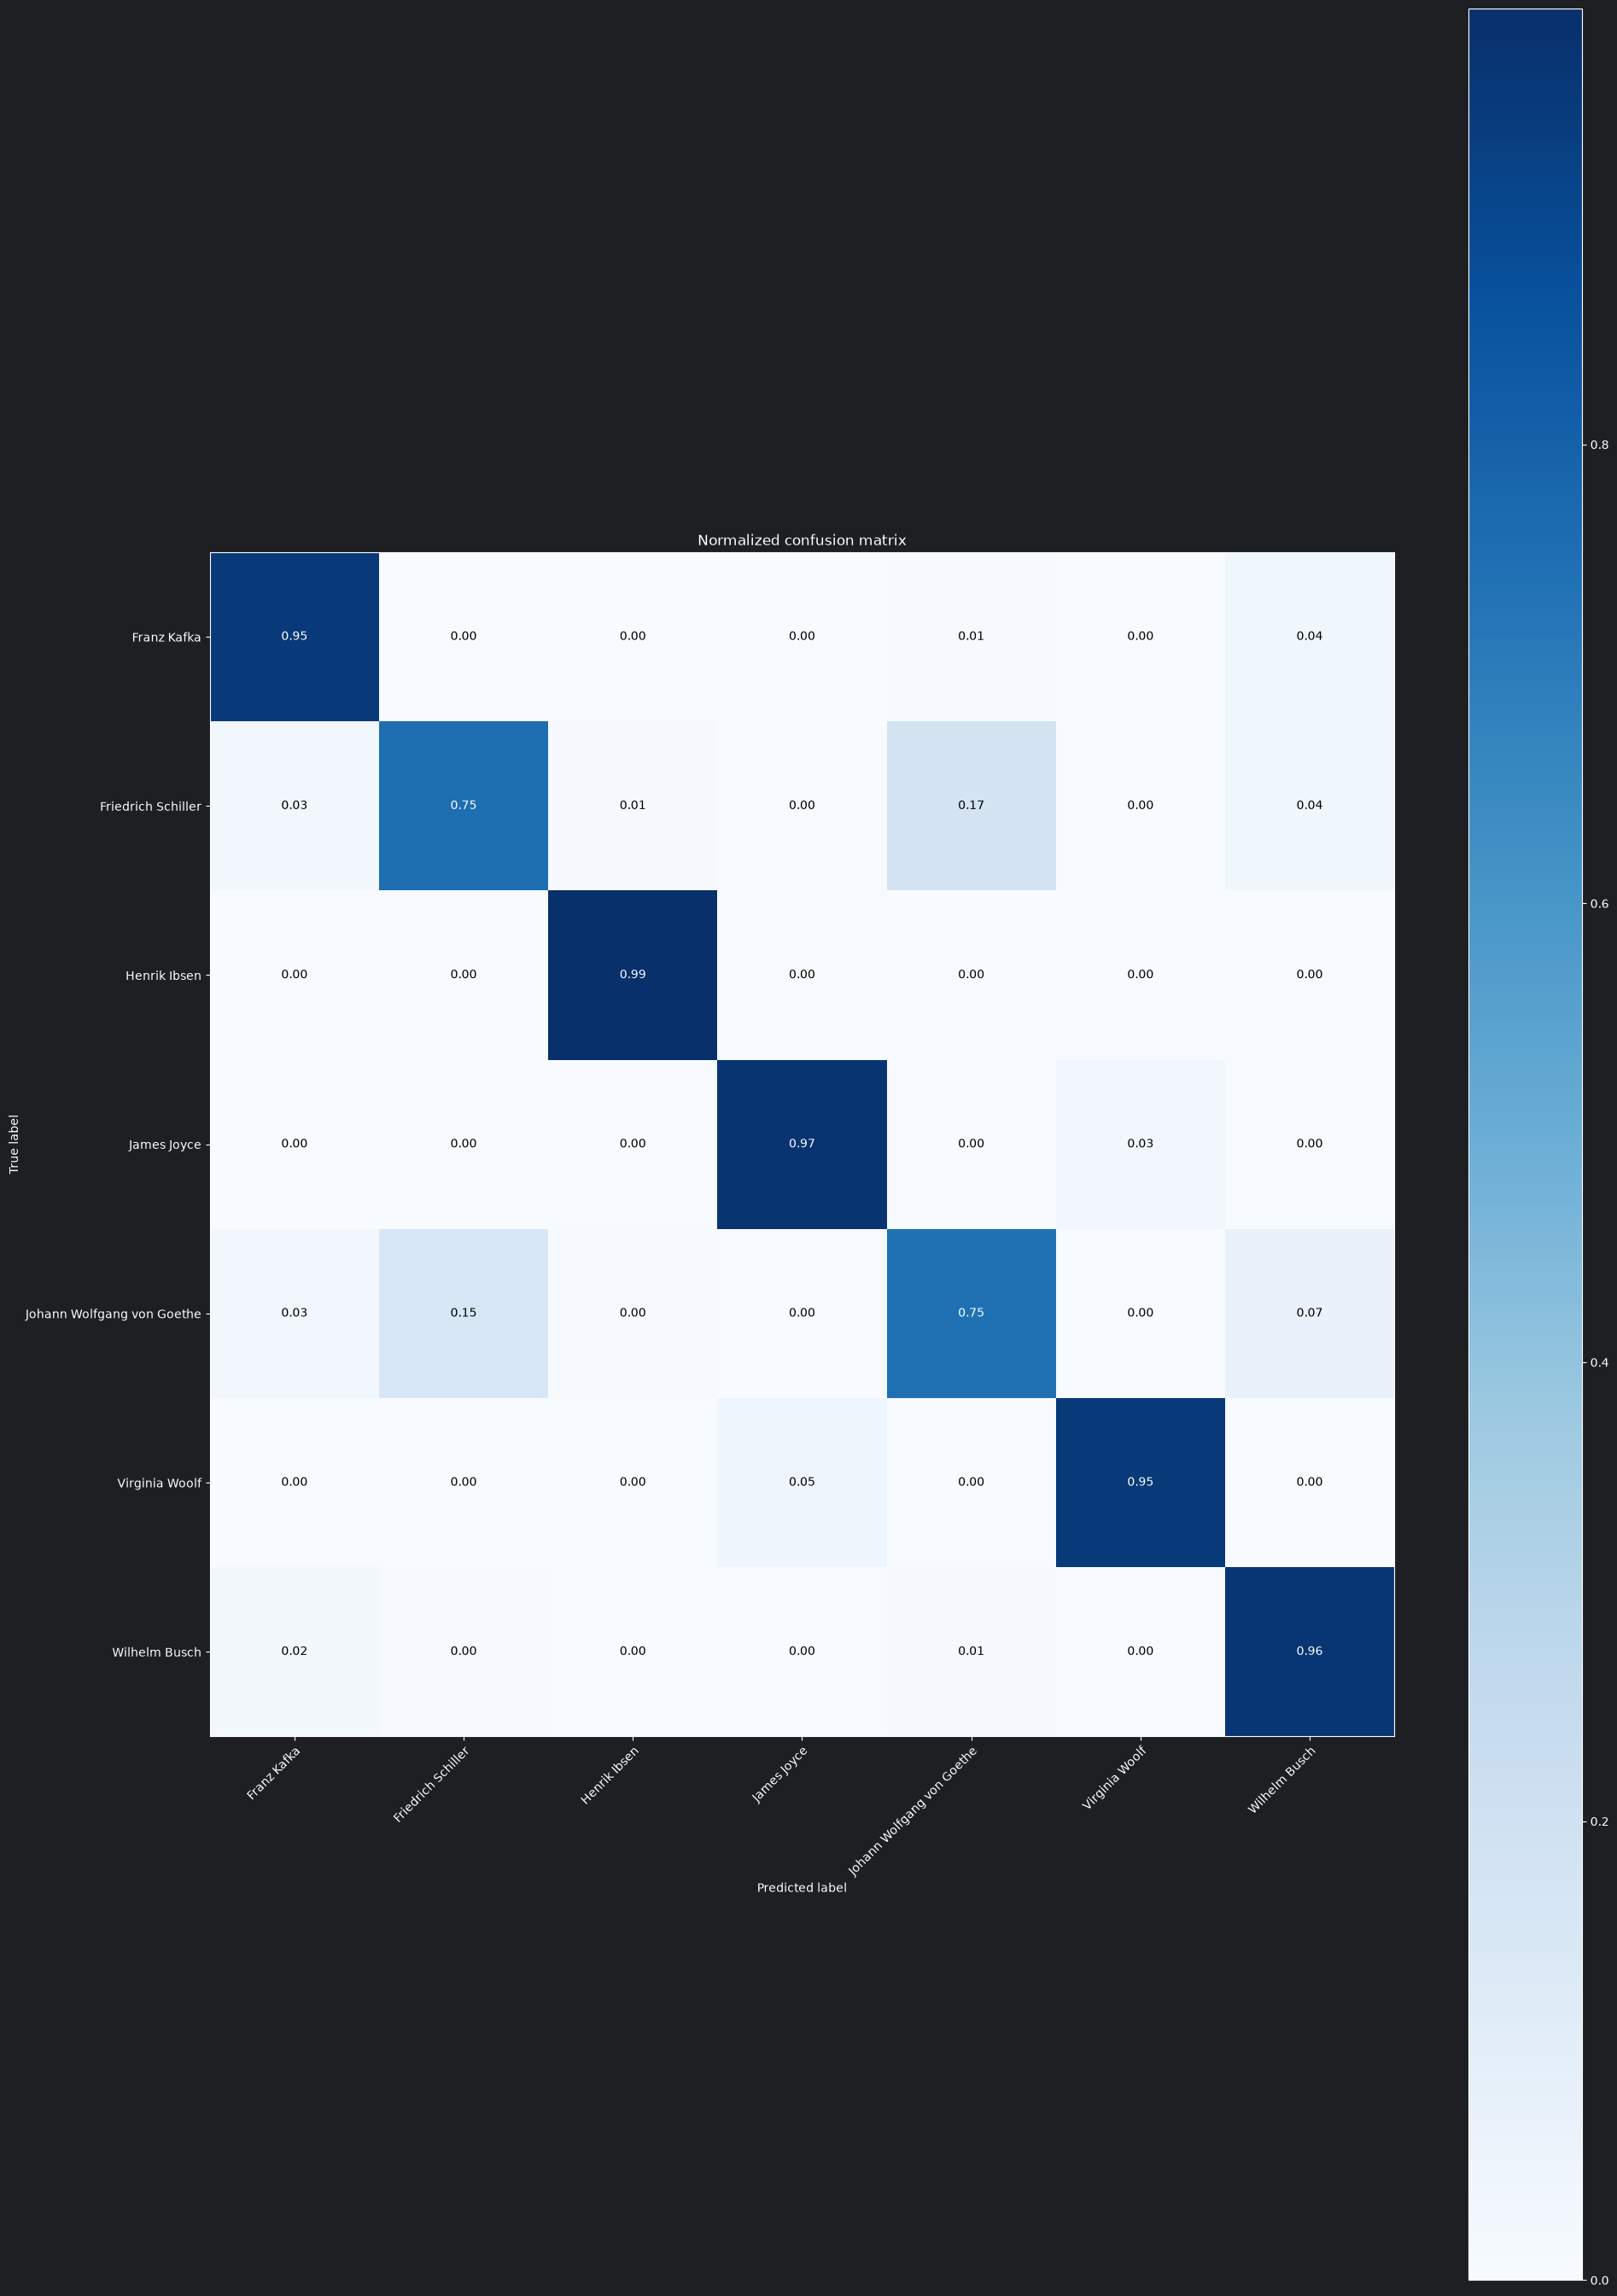

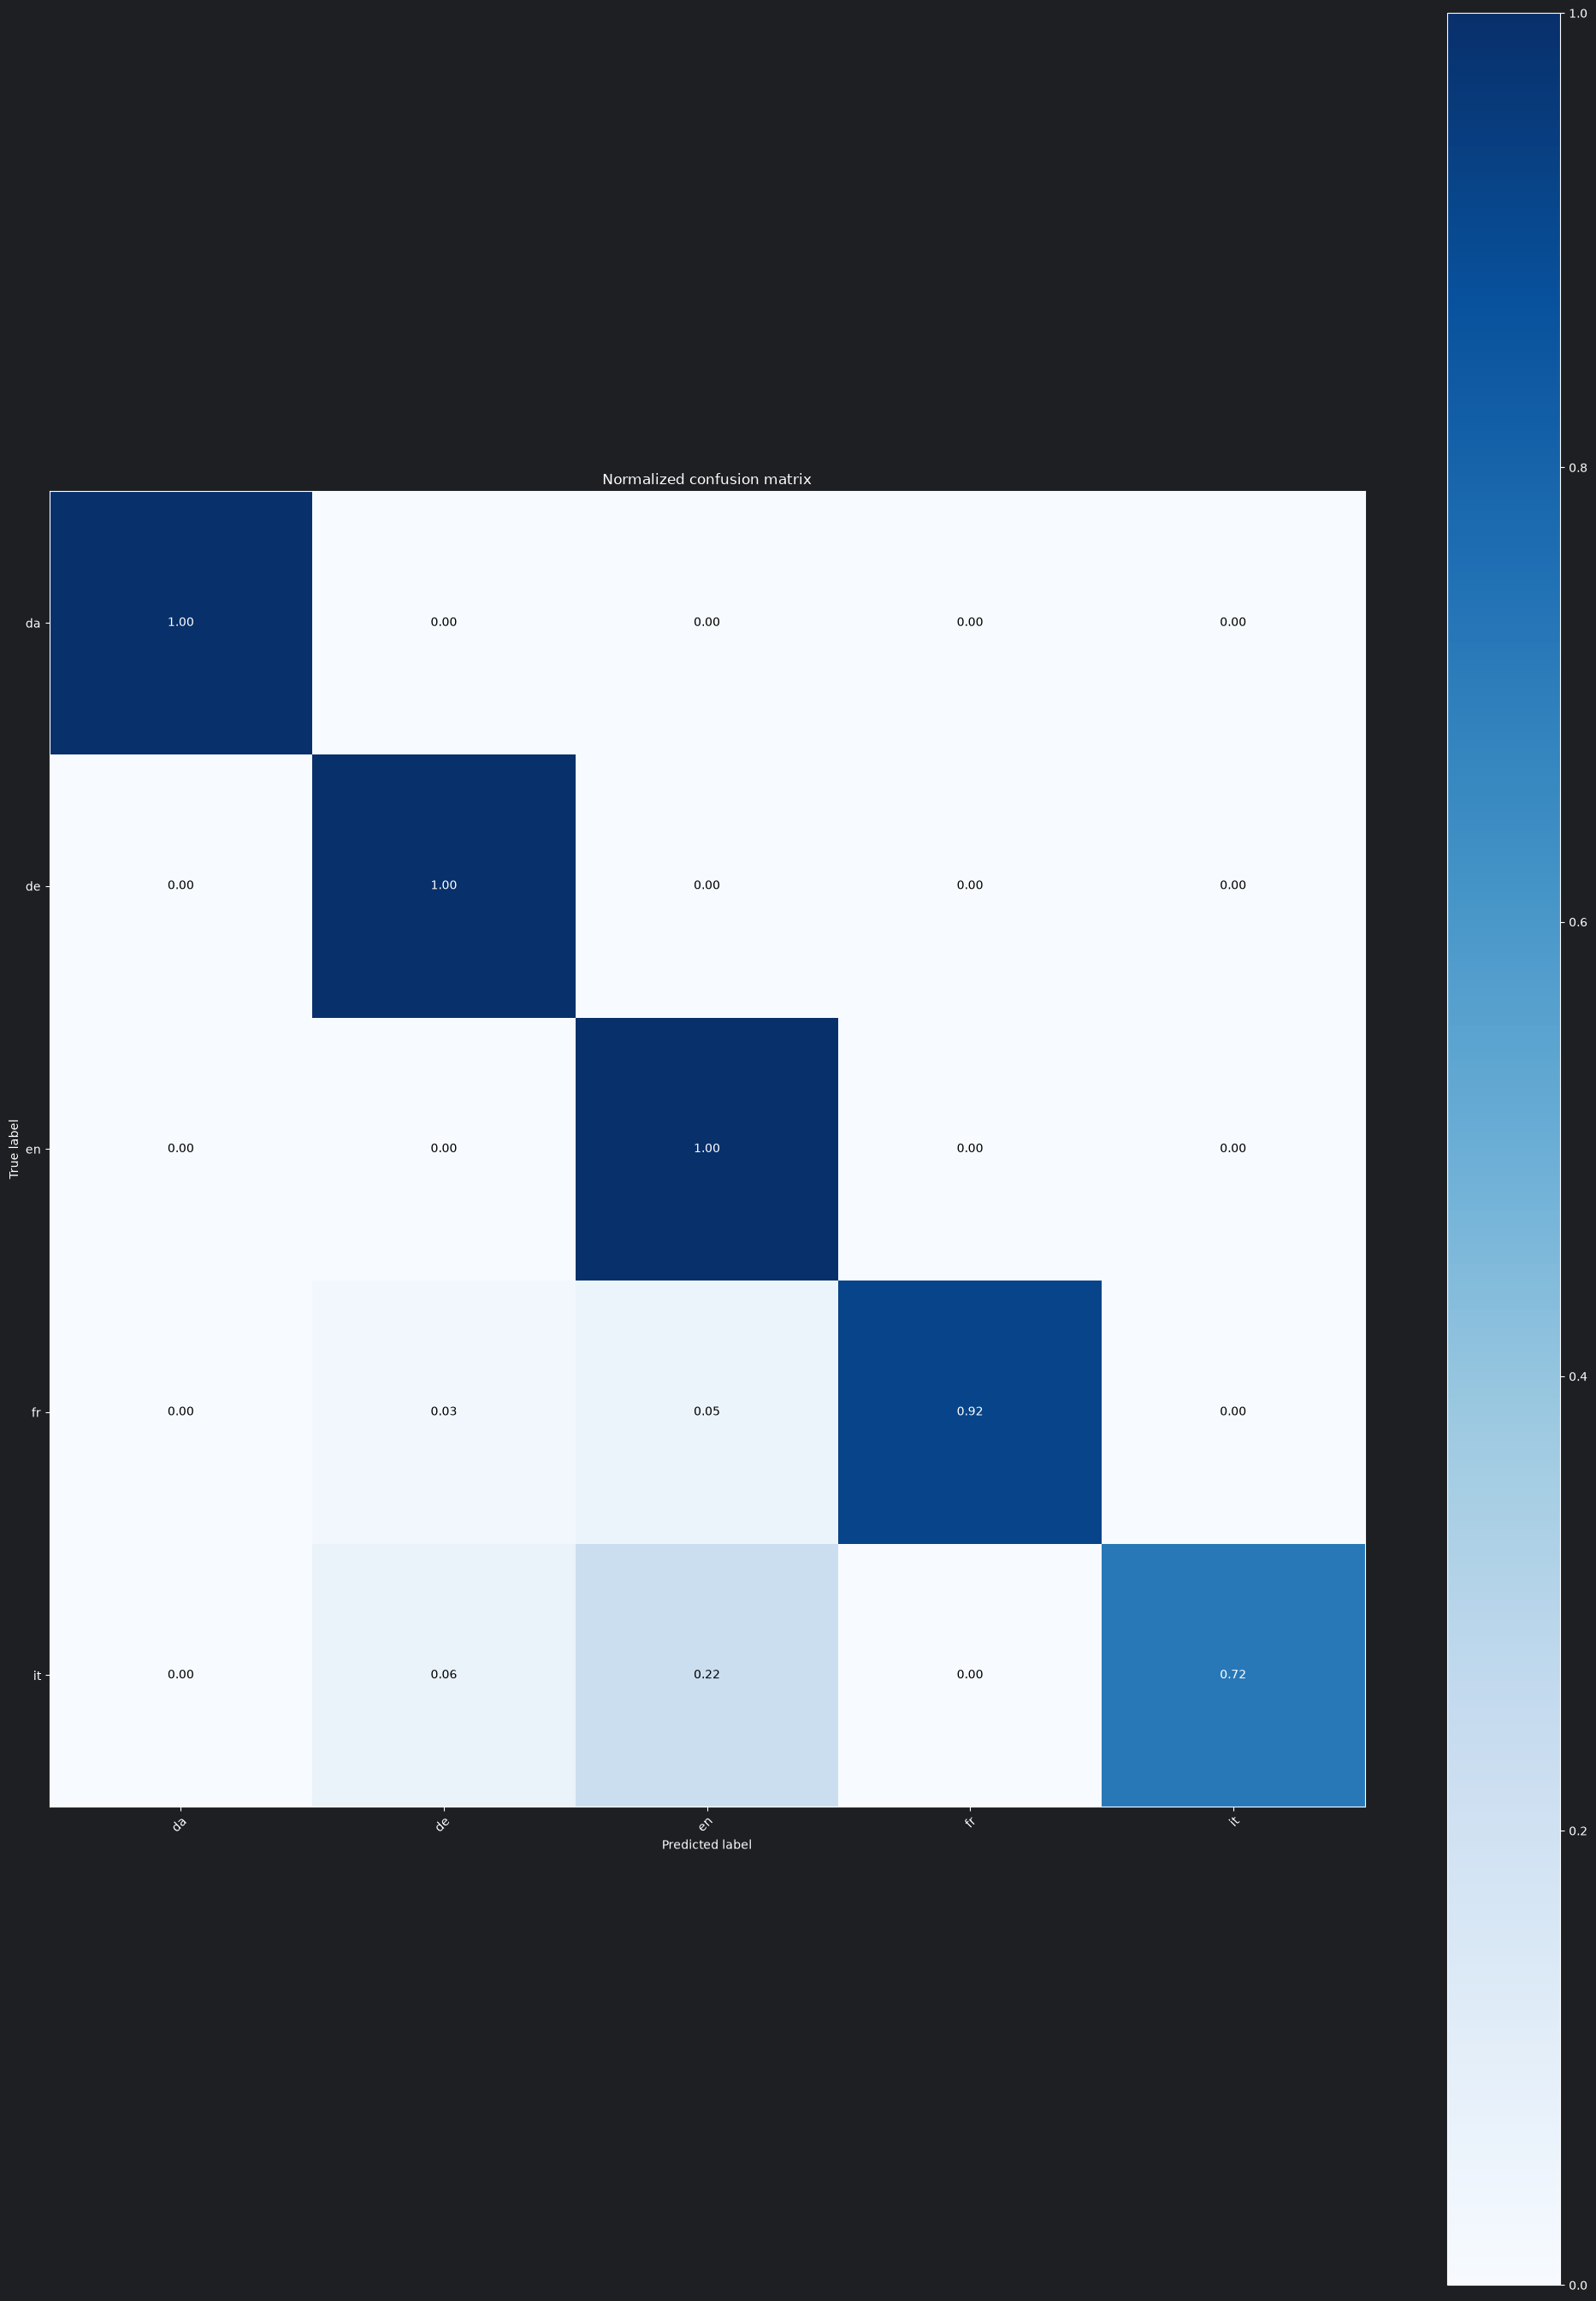

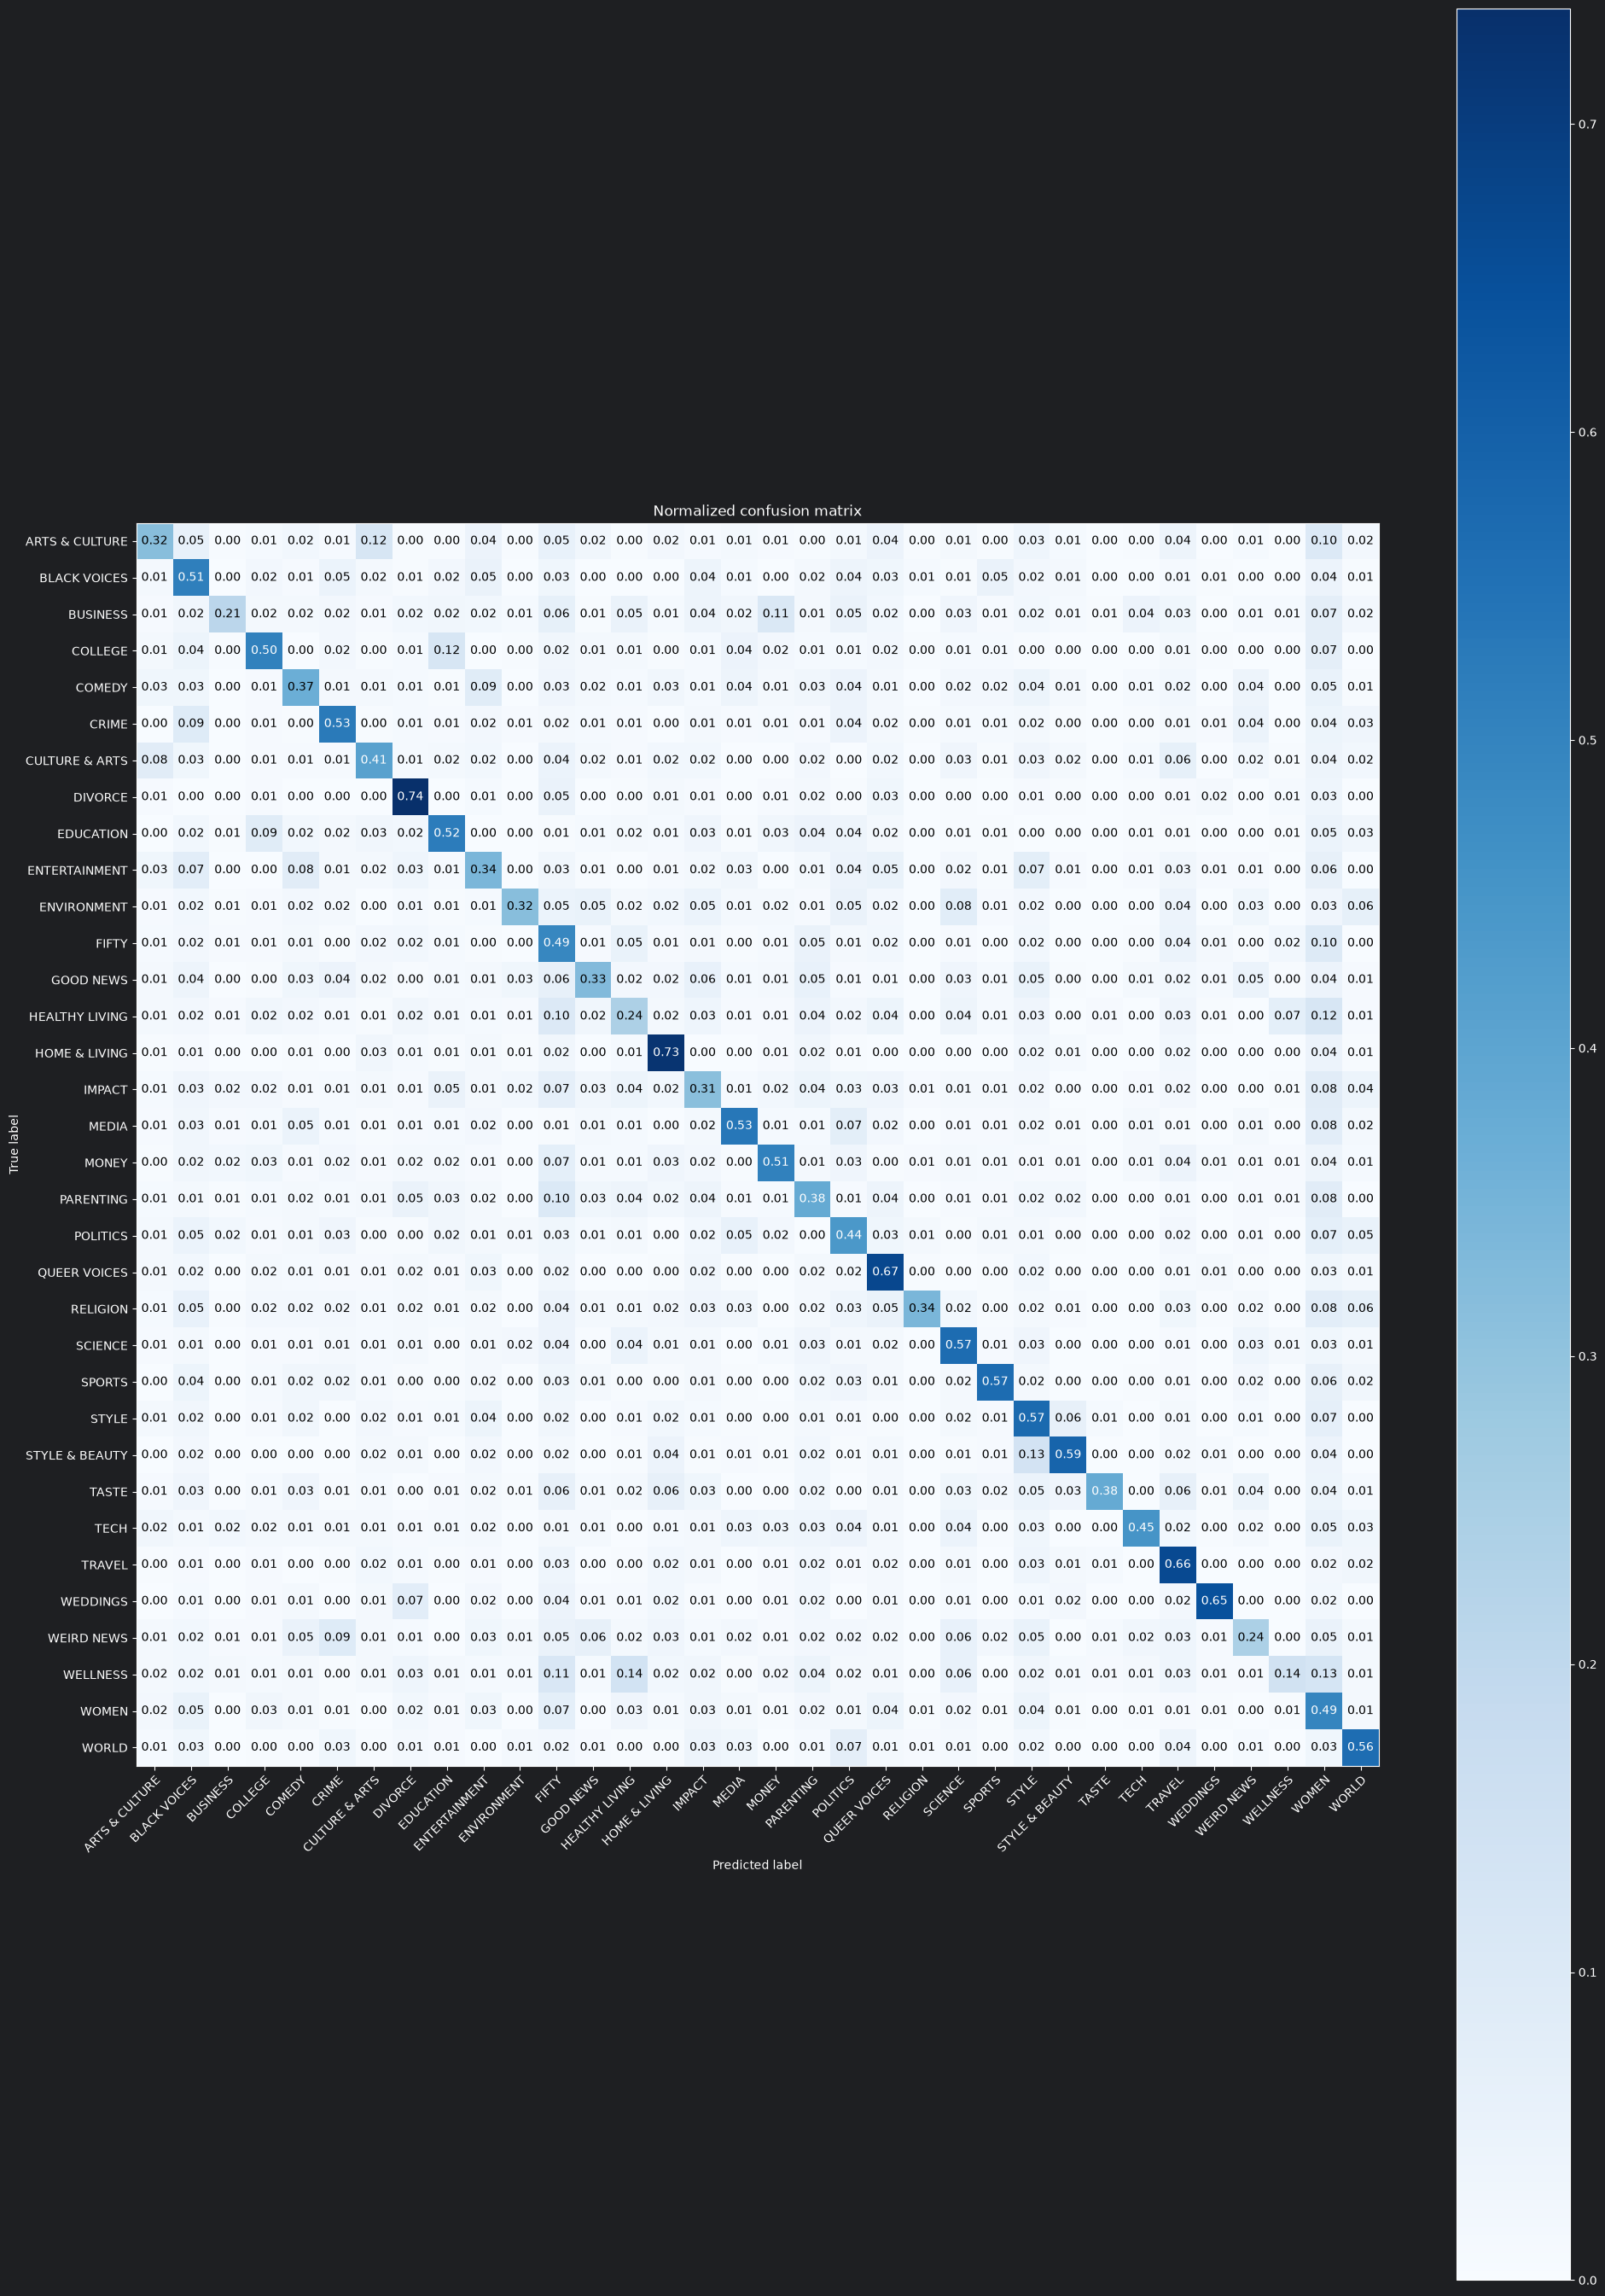

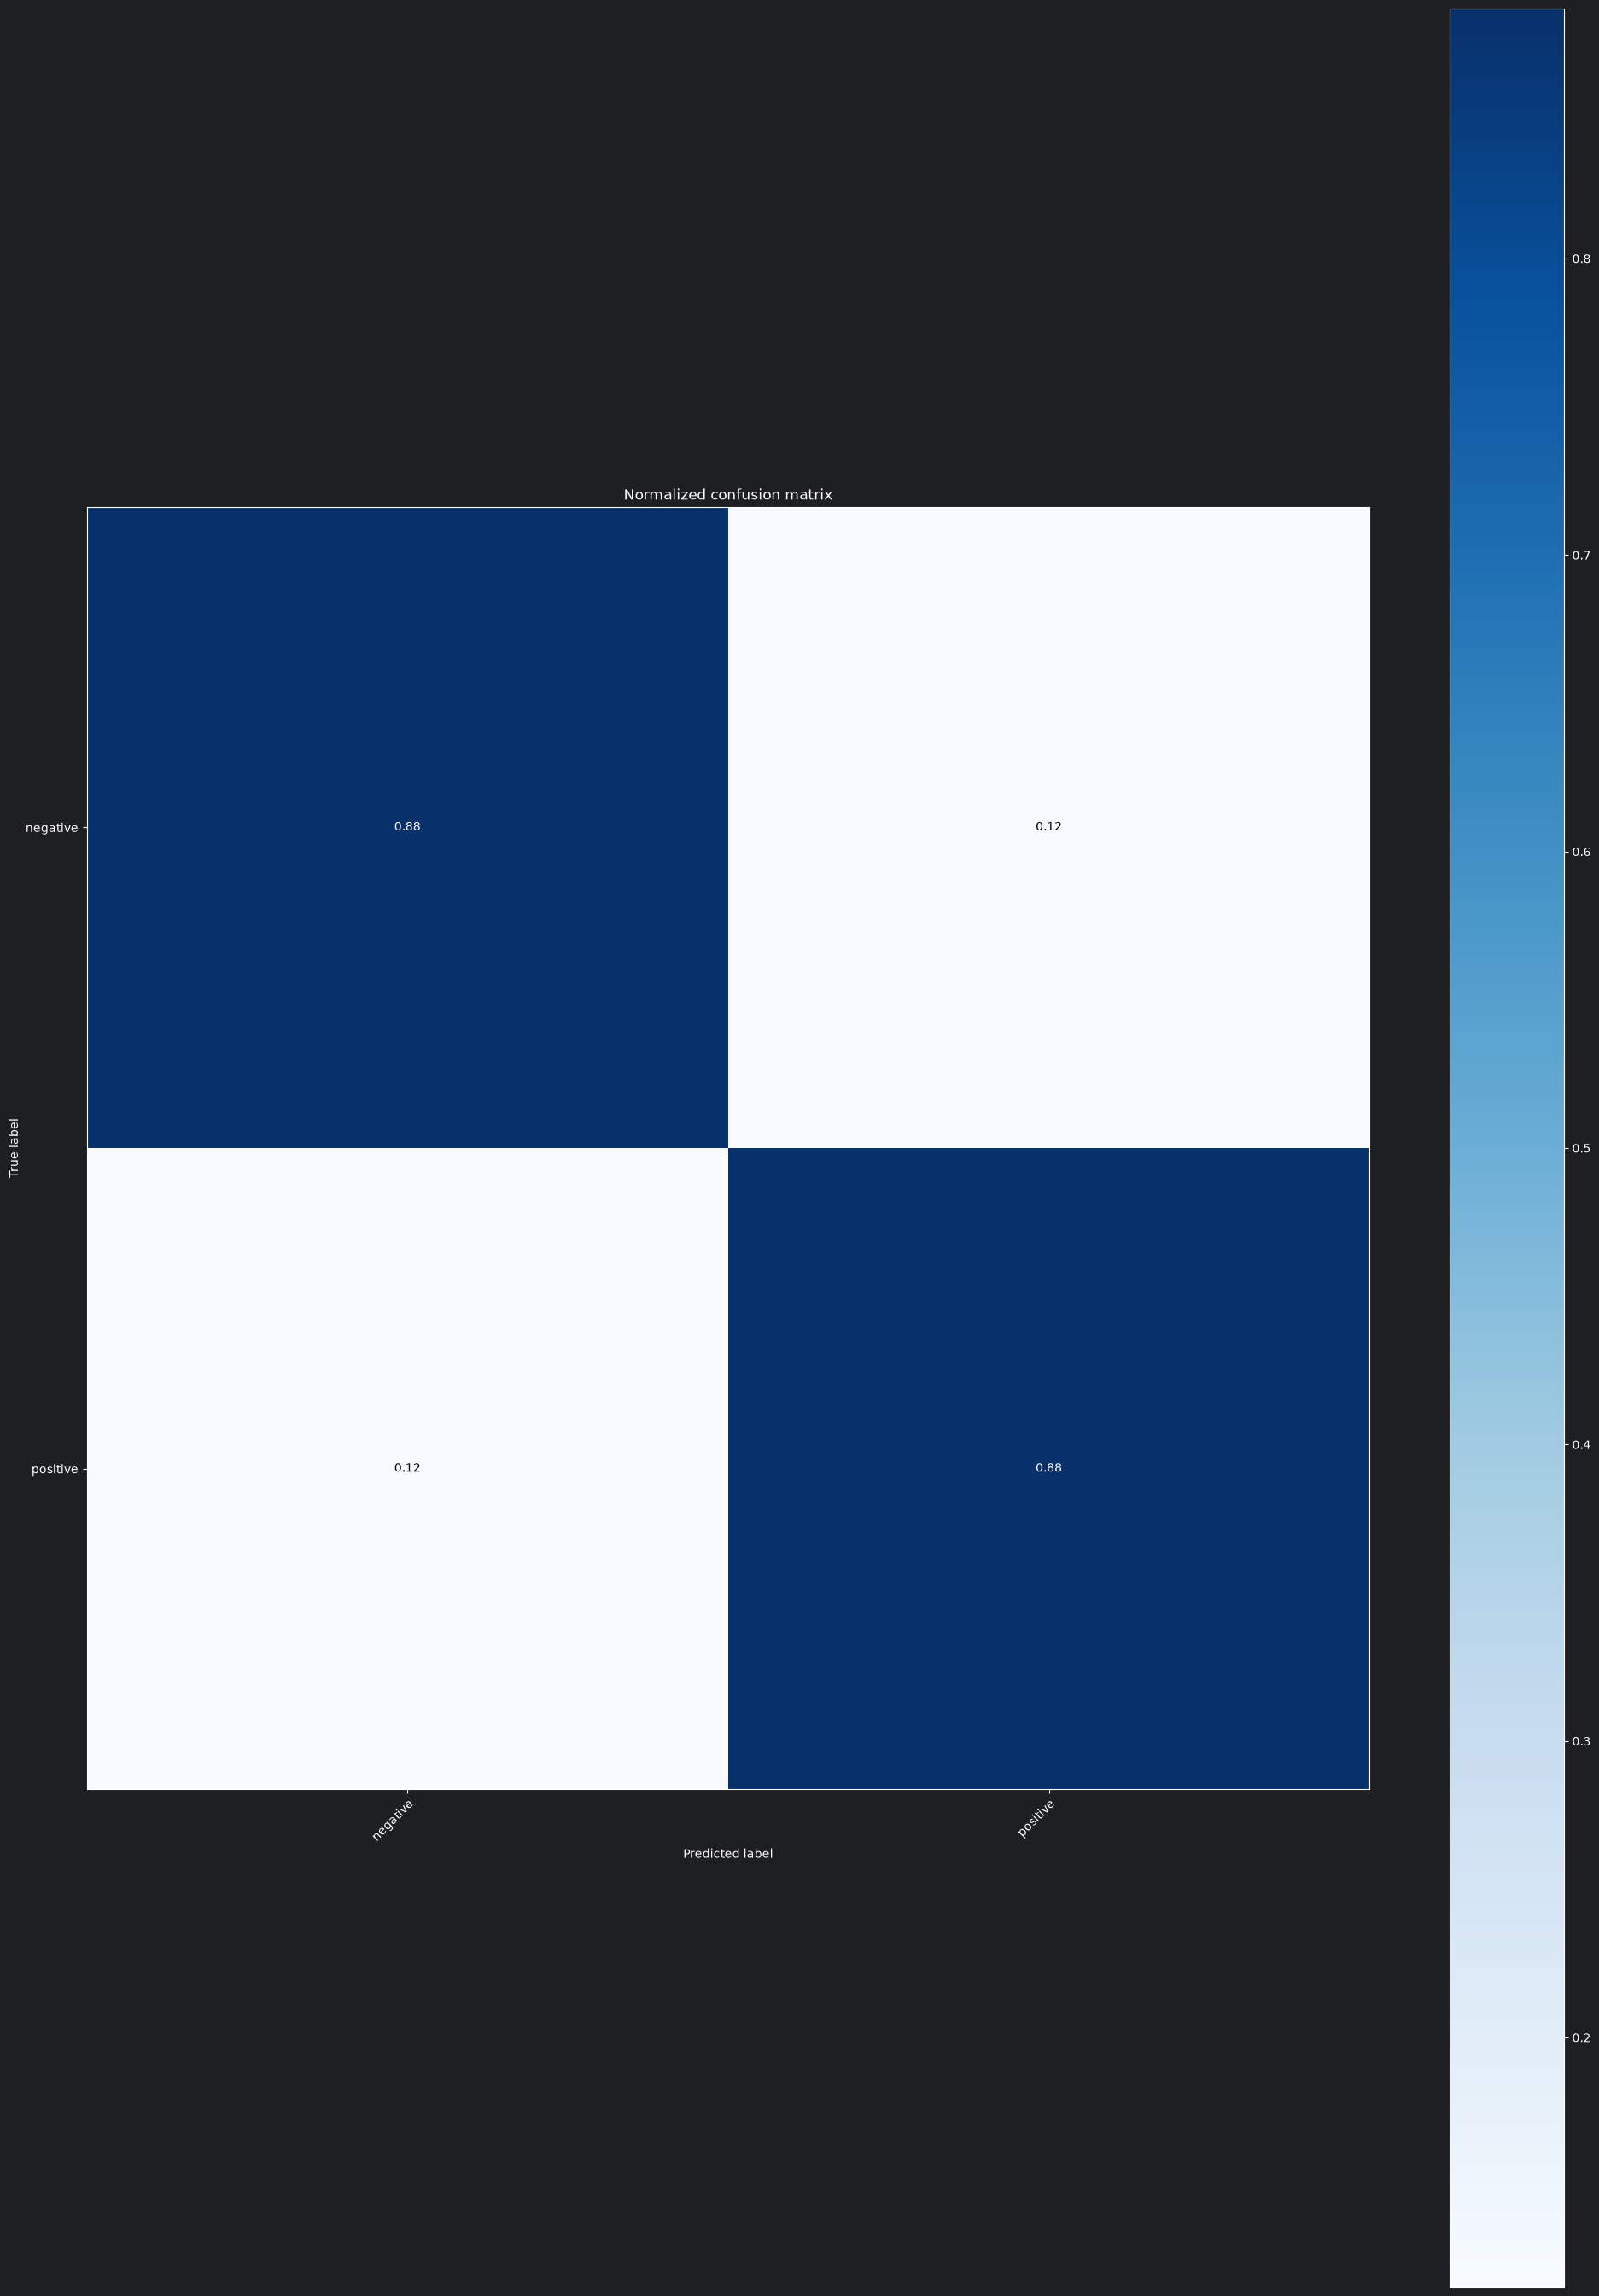

In [2]:
import os
# Convenience script (python) to run some classifiers
base_data_dir = r"C:/ProjectData/Projekte/Uni/classif_srch/data"
letters_data_dir = os.path.join(base_data_dir, "letters/classification")
news_data_dir = os.path.join(base_data_dir, "news/classification")
sentiment_data_dir = os.path.join(base_data_dir, "sentiment/classification")
print("start")
# Data description
# labels are the labels to use for classification
# text_label is the label comma separated list of text fields
data_configurations = [
    {
        "data_dir": letters_data_dir,
        "name": "letters",
        "labels"  : ["author", "lang"],
        "text_label" : "text"
    },
    {
        "data_dir": news_data_dir,
        "name": "news",
        "labels"  : ["category"],
        "text_label": "headline,short_description"
    },
    {
        "data_dir": sentiment_data_dir,
        "name": "sentiment",
        "labels"  : ["sentiment"],
        "text_label": "text"
    } 
]                       
  
# Classifier to use. You can use any scikit learn classifier listed in the python code  
# "DecisionTreeClassifier", "RandomForestClassifier", "LogisticRegression", "MLPClassifier",  
# "GaussianNB", "MultinomialNB", "KNeighborsClassifier", "LinearSVC", "Perceptron"  
classifier = "Perceptron"

print("Starting execution")
for configuration in data_configurations[0:3]:
    print(f"Executing configuration {configuration}")
    data_dir = configuration["data_dir"]
    eval_data = os.path.join(data_dir,"classifier_data_eval.jsonl")
    training_data = os.path.join(data_dir,"classifier_data_train.jsonl")
    results_data_dir = os.path.join(data_dir,"results")
    text_label = configuration["text_label"]
    labels = configuration["labels"]
    name = configuration["name"]
    for label in labels:
        output_label = f"{name}"
        print(f"Running classifier {classifier} on data {output_label} and label {label}")
        %run classify/run_classifier.py --classifier {classifier} --training {training_data} --input {eval_data} --output {results_data_dir} --label {label} --text_label {text_label}